<div style="background:linear-gradient(135deg,#1b1448 0%,#3b1f5e 55%,#7c2d12 100%);border-radius:18px;padding:34px 30px;color:#fff;font-family:Inter,Segoe UI,sans-serif">
  <div style="font-size:12px;letter-spacing:3px;color:#fed7aa;font-weight:700;text-transform:uppercase">Chapter 6 · How coding assistants work</div>
  <div style="font-size:34px;font-weight:900;line-height:1.1;margin:10px 0 6px">How coding assistants work</div>
  <div style="font-size:15px;color:#ffe4d6;max-width:740px;line-height:1.6">A coding assistant as a model in a loop with tools, built by hand on a small package, then read from the transcripts of the book's six Claude Code builds.</div>
  <div style="font-size:13px;color:#fed7aa;margin-top:14px">Building AI with AI: A Visual Handbook · John Fisher</div>
</div>

A coding assistant is a language model in a loop with tools. The model asks for a tool, the program around it runs the tool and sends back the result, and the loop continues until the model answers. This notebook builds that loop by hand, with two tools that read a small package, and runs it on Claude Sonnet 5.5. It then reads the kept transcripts of the book's six Claude Code builds, the same loop at work with Claude Code's own tools, and checks the guide this chapter's build wrote against the code it describes.

## Setup

This cell installs Anthropic's Python library and builds the client every call below goes through. It replays recorded answers unless you set `LIVE = True`.

In [1]:
# Set LIVE = True to send these requests to the Anthropic API with your own key, saved in
# Colab's secrets panel as ANTHROPIC_API_KEY. Left False, the notebook replays the answers
# recorded for the book, with no key and no cost.
LIVE = False
%pip install -q --disable-pip-version-check anthropic==2.7.0
import importlib, pathlib, sys, urllib.request
if "google.colab" in sys.modules:
    BASE = "https://raw.githubusercontent.com/johnfisher-ai/ai-with-ai/main/chapters/notebooks/"
    pathlib.Path("recordings").mkdir(exist_ok=True)
    for name in ["book_client.py", "recordings/how-coding-assistants-work.json"]:
        urllib.request.urlretrieve(BASE + name, name)
import book_client
importlib.reload(book_client)
client = book_client.make_client("how-coding-assistants-work", mode="live" if LIVE else None)

Note: you may need to restart the kernel to use updated packages.


Replaying 3 recorded responses from claude-sonnet-5-5, recorded 2026-11-12. Set LIVE = True in Setup to call the API yourself.


## The package the assistant reads

`supportdesk` is the repository of this chapter's build. It joins four modules Claude Code generated in Chapters 1, 3, 4 and 5 with `desk.py`, which the book wrote to triage a ticket, draft a reply with retries and price it. The cell loads the six files and counts their lines.

In [2]:
# The supportdesk package from this chapter's build: the modules Claude Code generated in Chapters 1, 3, 4
# and 5, and desk.py, which the book wrote to join them. Colab fetches the files from the book's repository.
BUILD = "how-coding-assistants-work"
FILES = ["__init__.py", "ask.py", "desk.py", "retry.py", "tokencost.py", "triage.py"]
if "google.colab" in sys.modules:
    PACKAGE = pathlib.Path("supportdesk")
    PACKAGE.mkdir(exist_ok=True)
    for name in FILES:
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/johnfisher-ai/ai-with-ai/main/builds/{BUILD}/given/supportdesk/{name}", PACKAGE / name)
else:
    PACKAGE = pathlib.Path("../../builds", BUILD, "given", "supportdesk")
for name in FILES:
    print(f"{name:13} {len((PACKAGE / name).read_text().splitlines()):>3} lines")

__init__.py     1 lines
ask.py         99 lines
desk.py        32 lines
retry.py       72 lines
tokencost.py   72 lines
triage.py      36 lines


## Two tools and their boundary

A tool is a name, a description and a JSON schema for its input. The model never runs a tool. It returns a `tool_use` block naming the tool and its input, and `run_tool` in this cell does the work. `read_file` accepts only the package's own file names, so whatever the model asks for, it can see these six files and nothing else.

In [3]:
import json

MODEL = "claude-sonnet-5-5"

# Two tools, described to the model as JSON schemas. The model asks for them, and this code runs them.
TOOLS = [
    {"name": "list_files", "description": "List the Python files in the supportdesk package.",
     "input_schema": {"type": "object", "properties": {}}},
    {"name": "read_file", "description": "Return the text of one file in the supportdesk package, such as desk.py.",
     "input_schema": {"type": "object", "properties": {"name": {"type": "string", "description": "The file name"}},
                      "required": ["name"]}},
]


def run_tool(name, args):
    # The tools can reach the package's own files and nothing else
    files = sorted(p.name for p in PACKAGE.glob("*.py"))
    if name == "list_files":
        return "\n".join(files)
    if name == "read_file" and args.get("name") in files:
        return (PACKAGE / args["name"]).read_text()
    return f"error: no file named {args.get('name')!r} in the package"


SYSTEM = ("You answer questions about the Python package supportdesk. Use the tools to read the code before you "
          "answer, and name the functions your answer relies on.")

## The loop, by hand

Each turn sends the conversation with the tool definitions. While the reply's `stop_reason` is `tool_use`, the cell runs each requested tool and sends the results back as `tool_result` blocks in a user message, with the model's reply kept in the history ahead of them. The loop ends when the model answers, or after eight requests.

In [4]:
QUESTION = ("What happens when the API answers with a 429 rate limit error while supportdesk is drafting a "
            "reply? Answer in a short paragraph.")

messages = [{"role": "user", "content": QUESTION}]
log = []
for turn in range(1, 9):
    reply = client.messages.create(model=MODEL, max_tokens=4096, system=SYSTEM, tools=TOOLS, messages=messages)
    messages.append({"role": "assistant", "content": reply.content})
    calls = [block for block in reply.content if block.type == "tool_use"]
    log.append({"turn": turn, "usage": reply.usage, "calls": [(c.name, c.input) for c in calls]})
    print(f"turn {turn}: stop_reason {reply.stop_reason!r}, {reply.usage.input_tokens} tokens in, "
          f"{reply.usage.output_tokens} out")
    if reply.stop_reason != "tool_use":
        break
    results = []
    for call in calls:
        output = run_tool(call.name, call.input)
        print(f"    {call.name}({json.dumps(call.input)}) -> {len(output)} characters")
        results.append({"type": "tool_result", "tool_use_id": call.id, "content": output})
    messages.append({"role": "user", "content": results})

answer = "".join(block.text for block in reply.content if block.type == "text")
print("\n" + answer)

turn 1: stop_reason 'tool_use', 528 tokens in, 26 out
    list_files({}) -> 58 characters
turn 2: stop_reason 'tool_use', 591 tokens in, 144 out
    read_file({"name": "desk.py"}) -> 1209 characters
    read_file({"name": "retry.py"}) -> 2134 characters
    read_file({"name": "ask.py"}) -> 3717 characters
turn 3: stop_reason 'end_turn', 3422 tokens in, 507 out

When the API returns a 429 while supportdesk is drafting a reply, `desk.handle` retries the call. It sends the draft through `retry.create_with_retries`, which turns off the SDK's own retries (`with_options(max_retries=0)`) and uses `call_with_retries` instead. `is_retryable` treats a 429 as retryable, as it does 408, 409, 5xx and connection errors. The one exception is a 429 whose body has the error code `enforced_spend_limit_reached`, which means a spend cap was hit. `_spend_cap_reached` detects that case, and the error is raised immediately.

For an ordinary rate limit, `call_with_retries` waits and tries again. The wait is t

The model took three requests. The first asked only for `list_files`. The second asked for `desk.py`, `retry.py` and `ask.py` in one reply, three tool calls the cell ran in turn. The third answered, and its input had grown from 591 to 3,422 tokens because the three files rode along in the history. The answer traces the retry path correctly, from `retry.create_with_retries` through `is_retryable` and `retry_after` to the exception that escapes `desk.main`. It also says plainly that it never opened `triage.py`, so it can't say whether triage is retried. One detail needs a reviewer, since "starts at about 1 second" describes the ceiling of the first wait, and `backoff_delay` waits a random fraction of it.

## What the model saw

The assistant knows only what the loop put in its context. The cell lists what it read and what it never opened.

In [5]:
read = [args["name"] for entry in log for name, args in entry["calls"] if name == "read_file"]
print("files read:", read)
print("files never opened:", sorted(set(FILES) - set(read)))
print(f"{len(log)} requests, {sum(e['usage'].input_tokens for e in log)} input tokens, "
      f"{sum(e['usage'].output_tokens for e in log)} output tokens in all")

files read: ['desk.py', 'retry.py', 'ask.py']
files never opened: ['__init__.py', 'tokencost.py', 'triage.py']
3 requests, 4541 input tokens, 677 output tokens in all


It read three of the six files and never opened `__init__.py`, `tokencost.py` or `triage.py`. The three requests read 4,541 input tokens and wrote 677, about 0.016 dollars at Claude Sonnet 5.5's prices as of November 2026. A coding assistant works the same way at a larger scale. Its picture of a repository is the files and command output it has pulled into its context, and its answers are only as complete as that reading.

## Six builds, read from their transcripts

Every Claude Code build in the book keeps a transcript of each step. The cell reads all six and counts the tool calls, the refused calls, the turns, the output tokens and the cost.

In [6]:
# The kept transcripts of the book's six Claude Code builds so far
SLUGS = ["what-building-ai-with-ai-means", "how-a-language-model-produces-text", "tokens-context-and-cost",
         "your-first-model-call", "reading-a-response", "how-coding-assistants-work"]
transcripts = {}
for slug in SLUGS:
    if "google.colab" in sys.modules:
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/johnfisher-ai/ai-with-ai/main/builds/{slug}/transcript.json", f"{slug}.json")
        path = pathlib.Path(f"{slug}.json")
    else:
        path = pathlib.Path("../../builds", slug, "transcript.json")
    transcripts[slug] = json.loads(path.read_text())

print(f"{'chapter':>7} {'tool calls':>10}  {'refused':>7} {'turns':>5} {'out':>5} {'dollars':>7}   tools in order")
for n, (slug, t) in enumerate(transcripts.items(), 1):
    calls = [s["tool"] for s in t["steps"] if s.get("tool")]
    refused = sum(1 for s in t["steps"] if s.get("denied"))
    r = t["result"]
    print(f"{n:>7} {len(calls):>10}  {refused:>7} {r['turns']:>5} {r['output_tokens']:>5} {r['cost_usd']:>7.4f}   "
          + " ".join(calls))

chapter tool calls  refused turns   out dollars   tools in order
      1          4        0     5   728  0.0162   Read Bash Edit Bash
      2          4        0     5  1049  0.0205   Read Bash Edit Bash
      3          4        0     5  1501  0.0285   Read Bash Edit Bash
      4          5        0     6  1843  0.0357   Read Bash Bash Edit Bash
      5          5        0     6  1337  0.0323   Read Bash Read Edit Bash
      6         11        1    12  3176  0.0648   Read Bash Bash Read Read Read Read Read Read Edit Bash


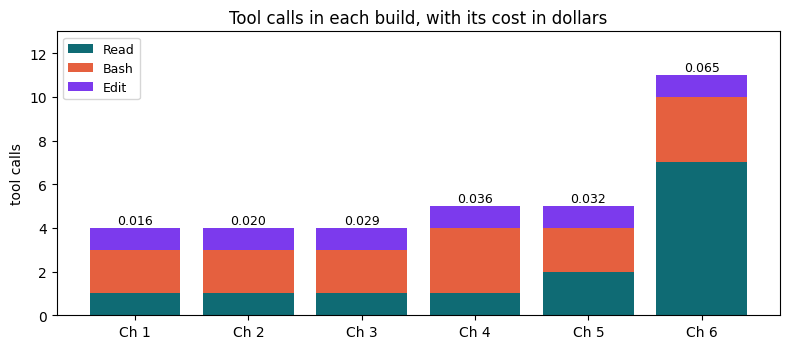

In [7]:
import matplotlib.pyplot as plt

colors = {"Read": "#0f6b74", "Bash": "#e5603f", "Edit": "#7c3aed"}
fig, ax = plt.subplots(figsize=(8, 3.6))
for n, t in enumerate(transcripts.values(), 1):
    calls = [s["tool"] for s in t["steps"] if s.get("tool")]
    bottom = 0
    for tool, color in colors.items():
        k = calls.count(tool)
        ax.bar(n, k, bottom=bottom, color=color, label=tool if n == 1 else None)
        bottom += k
    ax.text(n, bottom + 0.2, f"{t['result']['cost_usd']:.3f}", ha="center", fontsize=9)
ax.set_xticks(range(1, len(transcripts) + 1), [f"Ch {n}" for n in range(1, len(transcripts) + 1)])
ax.set_ylabel("tool calls")
ax.set_ylim(0, 13)
ax.legend(loc="upper left", fontsize=9)
ax.set_title("Tool calls in each build, with its cost in dollars", fontsize=12)
fig.tight_layout()
plt.show()

The first five builds took 4 or 5 tool calls each, the same pattern of read the spec, run the tests or look around the folder, write with Edit and run the tests. This chapter's build took 11. Explaining a package means reading it, and Claude Code opened the six source files one by one after its shell loop over them was refused. It also cost the most, 0.0648 dollars, with 3,176 output tokens, nearly twice the next most expensive build, because a guide is longer than a module and every file read added to the input of every later turn.

## The guide Claude Code wrote

The build asked Claude Code to read `supportdesk` and write `GUIDE.md` for an engineer joining the project. The first cell shows the guide. The second checks every function it names against the code, and tests the first gap it reports.

In [8]:
import ast
from IPython.display import Markdown, display

if "google.colab" in sys.modules:
    urllib.request.urlretrieve(f"https://raw.githubusercontent.com/johnfisher-ai/ai-with-ai/main/builds/{BUILD}/generated/GUIDE.md", "GUIDE.md")
    guide_path = pathlib.Path("GUIDE.md")
else:
    guide_path = pathlib.Path("../../builds", BUILD, "generated", "GUIDE.md")
guide = guide_path.read_text()
display(Markdown(guide))

# supportdesk guide

`supportdesk/` answers a support ticket in three steps: it sorts the ticket into a category, drafts a reply, and prices that reply.

## Modules

- `__init__.py` holds only a docstring; the package has no import-time code.
- `desk.py` is the entry point. `handle()` runs one ticket end to end and `main()` is the command line wrapper. It also holds the `SYSTEM` prompt for replies.
- `triage.py` sorts a ticket into one of `CATEGORIES` (billing, login, shipping, other). It defines `triage.triage()`, `triage.parse_category()`, `triage.normalize_label()` and its own `triage.answer_text()`.
- `ask.py` builds and sends plain requests. `ask.build_request()` validates the prompt, history and token limit and returns the request dict. `ask.answer_text()` joins the text blocks of a message, `ask.format_usage()` renders token counts, `ask.chat()` runs a multi-turn loop, and `ask.main()` is its own command line.
- `retry.py` wraps calls in retries. `retry.is_retryable()` decides whether an error is worth retrying, `retry.retry_after()` reads the `retry-after` header, `retry.backoff_delay()` computes a jittered exponential wait, `retry.call_with_retries()` is the loop, and `retry.create_with_retries()` applies it to `messages.create`.
- `tokencost.py` prices usage from the `PRICES` table. `tokencost.call_cost()` returns dollars, `tokencost.prompt_tokens()` totals the input side, `tokencost.context_check()` compares a prompt with the context window, and `tokencost.project_conversation()` lists usage for a growing conversation.

## How a ticket flows

1. `desk.handle()` receives the client and the ticket text.
2. It calls `triage.triage()`, which rejects an empty ticket, sends one `messages.create` request with the triage system prompt, and turns the reply into a category through `triage.answer_text()` and `triage.parse_category()`. The category is one of the four labels, or `unrecognized`.
3. `ask.build_request()` builds the drafting request from a prompt containing the category and ticket, with the `SYSTEM` prompt and the default model.
4. `retry.create_with_retries()` sends it using a client with the SDK's own retries turned off, and passes the call to `retry.call_with_retries()`, which retries errors that `retry.is_retryable()` accepts.
5. `tokencost.call_cost()` prices the message's usage for the request's model.
6. `ask.answer_text()` extracts the reply text, and `desk.handle()` returns a dict with `category`, `reply` and `cost`.

## Running it

```
export ANTHROPIC_API_KEY=your-key
python3 -m supportdesk.desk "My order arrived with a cracked screen."
```

The `anthropic` client reads the key from the `ANTHROPIC_API_KEY` environment variable. If no ticket is given as an argument, `desk.main()` reads it from standard input. It prints the category, the reply and the cost in dollars.

## Gaps and risks

- `triage.py`: `triage.normalize_label()` is never called, and it maps unknown labels to `other` while `triage.parse_category()` returns `unrecognized`. The two disagree, and `desk.py` puts `unrecognized` into the drafting prompt.
- `desk.py`: the triage call is not retried; only the drafting call goes through `retry.py`, so a transient error during triage fails the ticket.
- `desk.py`: `desk.main()` has no handling for an empty ticket or API errors, and the ticket text is placed directly into the prompt.
- `ask.py`: `ask.answer_text()` duplicates `triage.answer_text()` with slightly different behaviour, and the model name is repeated in `ask.py` and `triage.py`.
- `tokencost.py`: prices are hard-coded (`PRICES_AS_OF` is 2026-11) and only some models have long-prompt rates; `tokencost.call_cost()` raises for any model not in the table.
- `retry.py`: the retry loop sleeps in-process with no overall time limit beyond the attempt count.


In [9]:
import re, sys as _sys

# Every function the guide names, checked against the code it describes
defined = {}
for name in FILES:
    for node in ast.parse((PACKAGE / name).read_text()).body:
        if isinstance(node, ast.FunctionDef):
            defined.setdefault(node.name, []).append(name)
named = re.findall(r"`(?:([a-z_]+)\.)?([A-Za-z_]\w*)\(\)`", guide)
print(f"the guide names {len(named)} functions, {len(set(n for _, n in named))} distinct")
print("named but not defined:", sorted({n for _, n in named if n not in defined}))
print("defined twice:", {n: m for n, m in defined.items() if len(m) > 1})

# The guide's first gap: triage() parses the reply with parse_category(), never normalize_label()
_sys.path.insert(0, str(PACKAGE.parent))
from supportdesk import triage
for raw in ["billing", "Billing.", " login\n"]:
    print(f"{raw!r:12} parse_category -> {triage.parse_category(raw)!r:16} normalize_label -> {triage.normalize_label(raw)!r}")

the guide names 38 functions, 18 distinct
named but not defined: []
defined twice: {'answer_text': ['ask.py', 'triage.py'], 'main': ['ask.py', 'desk.py']}
'billing'    parse_category -> 'billing'        normalize_label -> 'billing'
'Billing.'   parse_category -> 'unrecognized'   normalize_label -> 'billing'
' login\n'   parse_category -> 'login'          normalize_label -> 'login'


The guide names 38 functions, 18 distinct, and every one exists in the package. It qualified the two names that are defined twice, `answer_text` in `ask.py` and `triage.py`, and `main` in `ask.py` and `desk.py`. Its first gap holds up when run. `triage()` turns the model's reply into a category with `parse_category()`, which returns `unrecognized` for `Billing.`, while the unused `normalize_label()` returns `billing`. That gap sat in the module Chapter 1's first build produced, which defined both functions because its spec asked for both. Chapter 1's build was then run again from a revised spec, and its `parse_category()` now cleans a reply before checking it, so `Billing.` reads as `billing`. The package here keeps the first build's module, the one Claude Code read.

## What the notebook showed

- An assistant is a loop. The model asks for tools, the program runs them, and the results go back until the model answers.
- The hand-built loop answered in three requests after reading three of six files, and said what it hadn't read.
- Each file read stays in the history, so the input grew from 591 to 3,422 tokens in one turn.
- The first five builds took 4 or 5 tool calls each, and explaining a package took 11.
- The guide named only functions that exist, and its first gap reproduces with `Billing.`.

---
<div style="text-align:center;color:#666f8e;font-size:12px;margin-top:10px">Building AI with AI: A Visual Handbook · © 2026 John Fisher · text CC BY 4.0, code MIT</div>